# Two-second clip distributions

Counts come from `split.csv`: each row is one selected two-second training example,
including windows read from full owl recordings. Overlapping windows count separately;
hours below are summed sample duration, not unique recording duration.

The first chart compares **pygmy, boreal and negative** samples. The second breaks
negatives down by their existing subclasses. Bar segments show train/validation/test.
All counts include every row in `split.csv`; flagged clips in `ambiguous.csv` are
**not excluded**. Rerun all cells after changing the split.

To run interactively, select the `owls` Python environment as the notebook kernel.


In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Run from the project folder, or set ROOT to its location.
ROOT = Path.cwd()
if not (ROOT / "split.csv").is_file():
    raise FileNotFoundError("Set ROOT to the project folder containing split.csv")
df = pd.read_csv(ROOT / "split.csv", keep_default_na=False)
required = {"class", "subclass", "recording", "start_s", "end_s", "split"}
assert required.issubset(df.columns), "Unexpected split.csv columns"
assert np.allclose(df.end_s - df.start_s, 2, rtol=0, atol=1e-5), "Non-two-second samples"
assert set(df["class"]) <= {"pygmy", "boreal", "negative"}
assert set(df["split"]) <= {"train", "validation", "test"}
assert (df.loc[df["class"].eq("negative"), "subclass"] != "").all()
SPLITS = ["train", "validation", "test"]
COLORS = ["#4477AA", "#EEAA33", "#228833"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
print(f"{len(df):,} two-second examples ({len(df) * 2 / 3600:,.2f} sample hours)")


66,228 two-second examples (36.79 sample hours)


## All classes

split,train,validation,test,total,share_percent,sample_hours
class,,,,,,
pygmy,15453,2208,4415,22076,33.33,12.26
boreal,15453,2208,4415,22076,33.33,12.26
negative,15454,2200,4422,22076,33.33,12.26


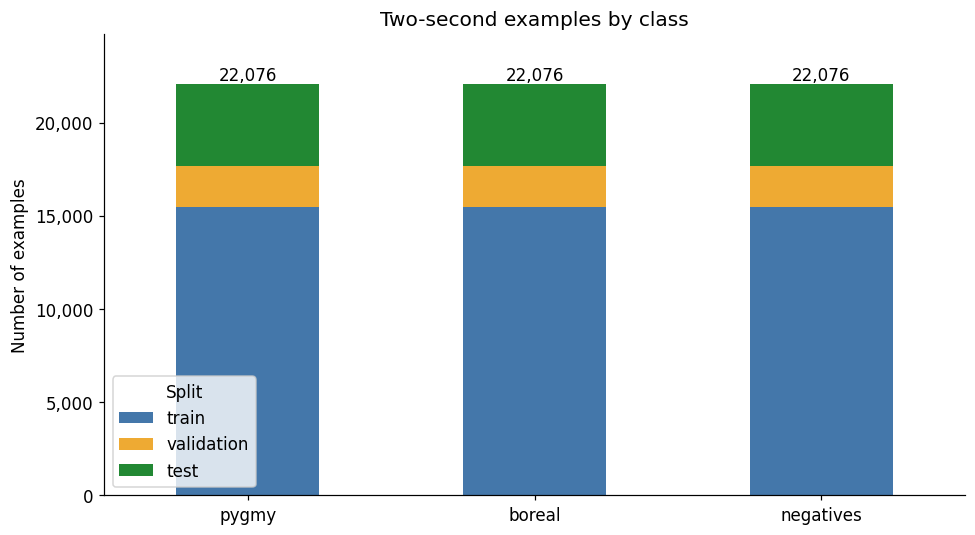

In [5]:
class_counts = pd.crosstab(df["class"], df["split"]).reindex(
    index=["pygmy", "boreal", "negative"], columns=SPLITS, fill_value=0)
class_summary = class_counts.copy()
class_summary["total"] = class_counts.sum(axis=1)
class_summary["share_percent"] = (class_summary.total / len(df) * 100).round(2)
class_summary["sample_hours"] = (class_summary.total * 2 / 3600).round(2)
display(class_summary)

ax = class_counts.rename(index={"negative": "negatives"}).plot.bar(
    stacked=True, color=COLORS, figsize=(9, 5), rot=0)
for i, total in enumerate(class_summary.total):
    ax.text(i, total, f"{total:,}", ha="center", va="bottom", fontsize=11)
ax.set(title="Two-second examples by class", xlabel="", ylabel="Number of examples")
ax.set_ylim(0, class_summary.total.max() * 1.12)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:,.0f}"))
ax.legend(title="Split")
plt.tight_layout()
plt.show()


## Negative subclasses

`owl_background_pygmy` and `owl_background_boreal` are negative windows taken
from the corresponding owl recordings. `risoux_background` contains the filtered
Risoux clips. Each scientific name identifies one of the 19 additional species.


split,train,validation,test,total,share_of_negatives_percent,sample_hours
subclass,,,,,,
Fringilla coelebs,703,100,201,1004,4.55,0.56
Otus scops,703,100,201,1004,4.55,0.56
Pyrrhula pyrrhula,703,100,201,1004,4.55,0.56
Regulus regulus,703,100,201,1004,4.55,0.56
Sitta europaea,703,100,201,1004,4.55,0.56
Strix aluco,703,100,201,1004,4.55,0.56
Troglodytes troglodytes,703,100,201,1004,4.55,0.56
Turdus merula,703,100,201,1004,4.55,0.56
owl_background_boreal,703,100,201,1004,4.55,0.56


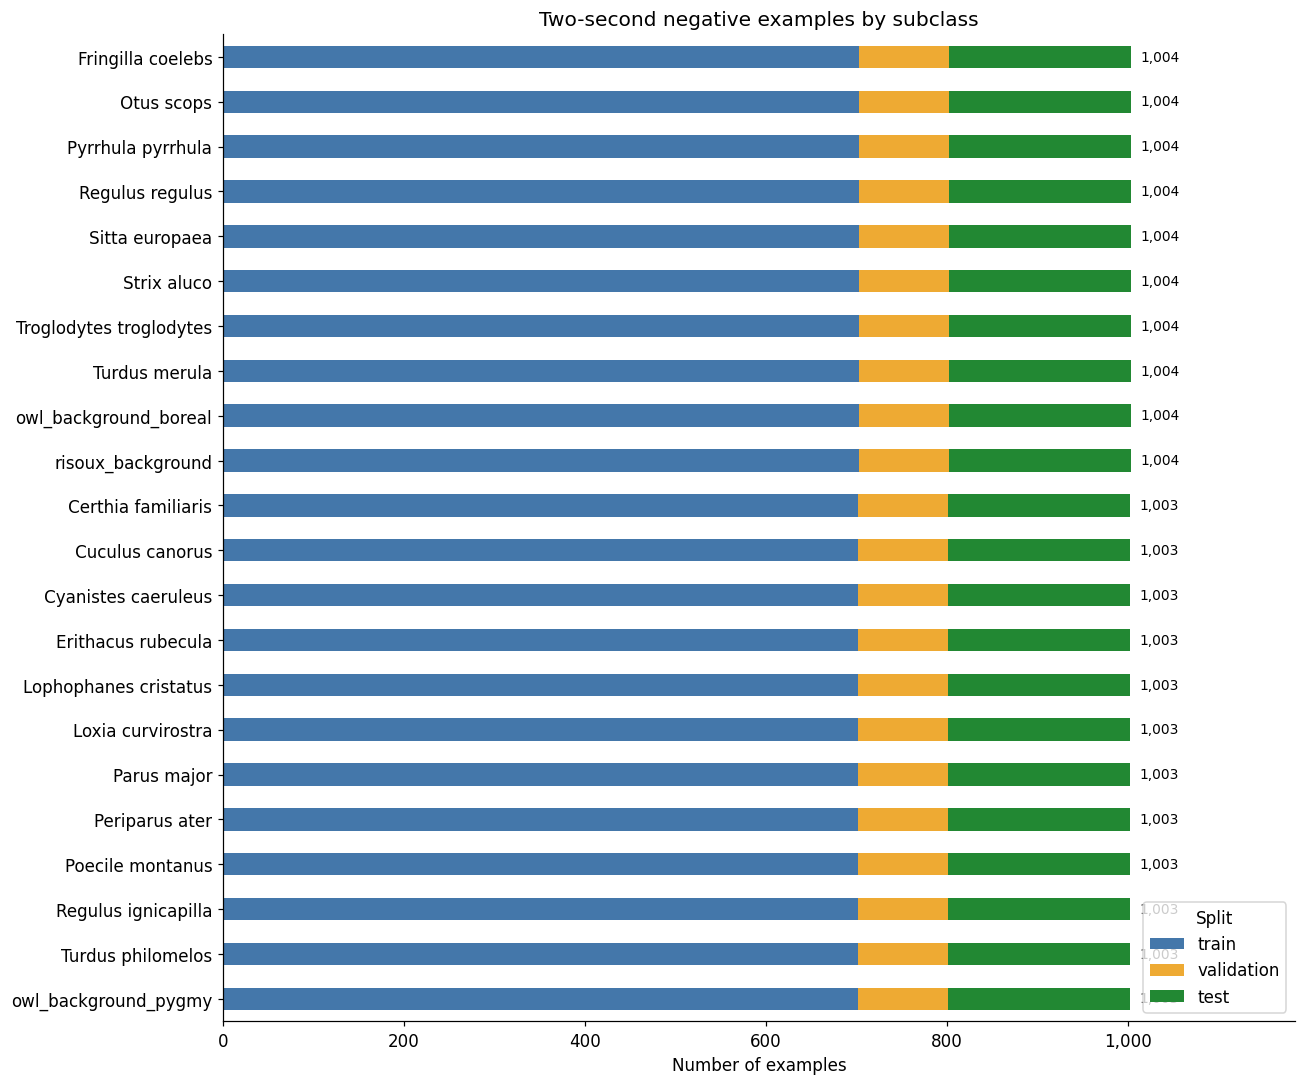

In [6]:
negatives = df.loc[df["class"].eq("negative")]
negative_counts = pd.crosstab(negatives.subclass, negatives["split"]).reindex(
    columns=SPLITS, fill_value=0)
order = negative_counts.sum(axis=1).sort_values(ascending=False, kind="stable").index
negative_counts = negative_counts.loc[order]
negative_summary = negative_counts.copy()
negative_summary["total"] = negative_counts.sum(axis=1)
negative_summary["share_of_negatives_percent"] = (negative_summary.total / len(negatives) * 100).round(2)
negative_summary["sample_hours"] = (negative_summary.total * 2 / 3600).round(2)
display(negative_summary)

ax = negative_counts.plot.barh(stacked=True, color=COLORS, figsize=(12, 10))
for i, total in enumerate(negative_summary.total):
    ax.text(total + negative_summary.total.max() * 0.01, i, f"{total:,}", va="center", fontsize=9)
ax.invert_yaxis()
ax.set(title="Two-second negative examples by subclass", xlabel="Number of examples", ylabel="")
ax.set_xlim(0, negative_summary.total.max() * 1.18)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:,.0f}"))
ax.legend(title="Split", loc="lower right")
plt.tight_layout()
plt.show()
